## LSTM Station Demand Forecast — v2 (bug fixes + Poisson loss)

Same architecture and split as `lstm_forecast.ipynb` (baseline test R² 0.839), with these fixes:

| # | Fix | Why |
|---|-----|-----|
| 0 | **Dedupe station-days** (sum counts, ride-weighted shape) | 812 station-days appear twice in the station table (station_id migration, e.g. `18062` → `CHI00715` on 2025-05-31) |
| 1 | **Reindex every station to the full calendar, fill 0** | zero-ride days were *missing rows*, so windows/lags were row-based not calendar-based and `is_open` was ~always 1 |
| 2 | **Rolling stats grouped per station** | `grp.shift(1).transform(...)` ran the rolling over the whole frame, crossing station boundaries |
| 3 | **Windows built on the full frame, then split by target date** | val/test each lost their first `SEQ_LEN` days; test set now matches XGBoost's |
| 4 | **Head outputs log-rate, no final ReLU** | ReLU on the output has zero gradient when negative (dead output); log-rate is what Poisson needs |
| 5 | **Target-day weather = forecast for all splits; window weather = actual** | val used actual weather, test used forecast → early stopping on an optimistic val |
| 6 | **Pre-stacked on-device tensors, no per-epoch train re-eval** | per-sample `__getitem__` + a full extra train pass per epoch dominated runtime |

`LOSS_MODE` switches between `"poisson"` (default) and `"mse"` (scaled target, Softplus output) for an apples-to-apples comparison.

### v3 — external features (picked by the XGBoost Poisson ablation in `scripts/validate_features_xgb.py`)

| Group | Columns | Where | XGB Δ test R² (alone) |
|---|---|---|---|
| Station aliases | `canonicalize_stations()` — renames merged (`Lake Shore Dr`→`DuSable…`, `X*`, `Public Rack - X`) | cell 4 | 153 → 164 stations pass the 99 % filter |
| Weather | all 19 Open-Meteo vars (actual in window, forecast on target day) | window + head | **+0.015** |
| Holidays | US/IL holiday, major, eve/after/bridge, Christmas week | window + head | **+0.009** |
| City events | 16 event flags + `evdist_*` (flag × e^(−d/1.5 km)) | window + head | +0.004 |
| Sports | day game / playoff / n_games per venue + `evdist_*` (attendance dropped: only known post-game) | window + head | +0.002 |
| Academic | nearest university in session / term week / finals / remote | window + head | +0.001 |
| Capacity | dock `capacity`, `is_charging` | static | +0.001 |
| Flow | yesterday's inbound / net flow / 7-day net / inbound e-bike share | window | −0.003 alone, but `inbound_lag1` is the #3 feature in the all-in model |
| Calendar | Fourier day-of-year / weekday, station × weekday profile (`days_since_start` dropped: extrapolates on test) | window | −0.003 alone, useful in combination |
| *(spatial)* | kNN / city lags — **excluded**, no gain | — | −0.000 |

All groups together: XGB Poisson test R² 0.871 → **0.894**, sMAPE 30.4 → 27.5, MASE 0.587 → 0.523.


### v4 — regularisation + Negative Binomial

- `DROPOUT = 0.2` between LSTM layers, on the station/geo embedding and inside both heads; `PATIENCE = 10` (Poisson val plateaued by epoch 3 in v2, so 30 was dead time).
- `LOSS_MODE = "nb"`: NB2 likelihood with a per-sample dispersion head (`log_alpha`, initialised as a global constant). v2 Pearson residual std was 1.84–1.95 under Poisson, i.e. variance ≈ 3.5× the mean — Poisson is misspecified; NB learns the extra variance instead of forcing it into the mean.

### v6 — surge / plunge alerts from the NB distribution

`P(surge) = P(y > y_prev + 50)` and `P(plunge) = P(y < y_prev − 50)` are read straight off NB(μ, α); no extra head (a pos-weighted surge/plunge head was tried and lost to this on AP while costing 0.003 demand R²). Operating points are reported precision-first because a false alarm means a truck dispatched for nothing. Default `LOSS_MODE` is now `"nb"`.


## 1. Setup & Data Prep

In [1]:
import math, os, time, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F

from divvy_demand.infra.s3_client import S3Client
from divvy_demand.station_meta import collapse_meta
from divvy_demand.features import (canonicalize_stations, add_fourier_calendar, add_station_dow_profile,
                                   add_event_distance_interactions, add_university_session, haversine_km)

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather      = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

# ---- v3 feature tables (see scripts/validate_features_xgb.py for the ablation that picked these) ----
meta         = s3.read_processed('station_meta')                       # coords, capacity, canonical_name
sports_daily = s3.read_processed('events/sports_daily')                # per-venue attendance / day game / playoff
holidays     = s3.read_processed('events/holidays').drop(columns=['holiday_name'])
city_events  = s3.read_processed('events/city')                        # long table: event, date, lat, lng
academic     = s3.read_processed('events/academic')                    # university terms
flow         = s3.read_processed('station_flow')                       # inbound / net flow (canonical names)
for t in (sports_daily, holidays, city_events, flow):
    t['date'] = pd.to_datetime(t['date'])

print('Station:', station.shape)
print('Weather (hist):', weather.shape, '| Weather (fcst):', weather_fcst.shape)
print('Meta:', meta.shape, '| sports_daily:', sports_daily.shape, '| holidays:', holidays.shape,
      '| city:', city_events.shape, '| academic:', academic.shape, '| flow:', flow.shape)


Station: (1402616, 37)
Weather (hist): (2251, 20) | Weather (fcst): (2251, 20)
Meta: (2507, 12) | sports_daily: (2557, 23) | holidays: (2557, 25) | city: (233, 6) | academic: (141, 9) | flow: (1503477, 7)


In [2]:
# ---- Config -----------------------------------------------------------------
LOSS_MODE  = "nb"           # "poisson" | "nb" | "mse"   (nb: best point forecast + calibrated spread, see v4/v6)
SEQ_LEN    = 7
HIDDEN     = 128
NUM_LAYERS = 5
STN_DIM    = 16
GEO_DIM    = 16
N_FOURIER  = 6
BATCH_SIZE = 512
EPOCHS     = 300
LR         = 1e-3
WEIGHT_DECAY = 1e-5
PATIENCE   = 10             # v4: Poisson val plateaus by epoch ~3; 30 just burned time
DROPOUT    = 0.2            # v4: between LSTM layers + inside both heads
MIN_DELTA  = 1e-7
BCE_WEIGHT = 0.01 if LOSS_MODE == "mse" else 1.0   # Poisson NLL is ~3 orders of magnitude larger than MSE on [0,1]
SEED       = 42

torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"LOSS_MODE={LOSS_MODE}  device={device}")

LOSS_MODE=nb  device=mps


In [3]:
# ---- Fix 0 (v3): merge station aliases + dedupe (station, date) -------------------------------
# canonicalize_stations() maps every name to station_meta.canonical_name (renames such as
# 'Lake Shore Dr' -> 'DuSable Lake Shore Dr', 'X' vs 'X*', 'X' vs 'Public Rack - X') and then merges
# rows that collide on (date, station): counts summed, shape columns ride-weighted. This also covers
# the station_id-migration duplicates the old hand-written dedupe handled.
COUNT_COLS = ['total_rides', 'ebike_rides', 'member_rides', 'casual_rides']
HOUR_COLS  = [f"hour_{h:02d}_pct" for h in range(24)]
QUANT_COLS = [f"mh_dist_p{q:02d}_km" for q in [10, 25, 50, 75, 90]]
SHAPE_COLS_BASE = HOUR_COLS + ["frac_round_trips"] + QUANT_COLS

n_before, n_names = len(station), station['start_station_name'].nunique()
station = canonicalize_stations(station, meta)
assert not station.duplicated(['start_station_name', 'date']).any()
print(f"Canonicalized: {n_before:,} -> {len(station):,} rows, {n_names} -> {station['start_station_name'].nunique()} stations")


Canonicalized: 1,402,616 -> 1,395,453 rows, 2507 -> 1981 stations


In [4]:
# Filter to stations active on >99% of days (same rule as baseline, so the station set is comparable)
n_days = station['date'].nunique()
min_active_days = int(0.99 * n_days)
active_stations = (
    station.groupby('start_station_name')['date'].nunique()
    .loc[lambda s: s > min_active_days].index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
print(f'Stations kept (>{min_active_days}/{n_days} days): {len(active_stations)}')

# ---- Fix 1: reindex to the full calendar; a missing station-day is a zero-ride day -----
full_dates = pd.date_range(station['date'].min(), station['date'].max(), freq='D')
idx = pd.MultiIndex.from_product([sorted(active_stations), full_dates], names=['start_station_name', 'date'])
n_before = len(df)
df = df.set_index(['start_station_name', 'date']).reindex(idx).reset_index()
df['is_zero_day'] = df['total_rides'].isna().astype(int)
df[COUNT_COLS] = df[COUNT_COLS].fillna(0)
df['start_station_id'] = df.groupby('start_station_name')['start_station_id'].transform(lambda s: s.ffill().bfill())
# shape cols stay NaN on zero days — rolling means skip NaN, scaler fills 0 later
print(f'Zero-ride days filled: {len(df) - n_before:,} ({(len(df) - n_before) / len(df):.2%} of rows)')
df = df.sort_values(['start_station_name', 'date']).reset_index(drop=True)

Stations kept (>2226/2249 days): 164
Zero-ride days filled: 2,176 (0.59% of rows)


## 2. Feature Engineering

In [5]:
# Station coords + dock capacity from station_meta (one row per canonical station)
cmeta = collapse_meta(meta).rename(columns={'lat': 'start_lat', 'lng': 'start_lng'})
df = df.merge(cmeta[['start_station_name', 'start_lat', 'start_lng', 'capacity', 'is_charging']],
              on='start_station_name', how='left')
df['capacity']    = df['capacity'].fillna(cmeta['capacity'].median())
df['is_charging'] = df['is_charging'].fillna(0)
print(f"Rows missing coords: {df[['start_lat', 'start_lng']].isna().any(axis=1).sum()}")

VENUES = {
    'wrigley': (41.9484, -87.6553),
    'grf':     (41.8299, -87.6338),
    'uc':      (41.8807, -87.6742),
    'soldier': (41.8623, -87.6167),
}
UNIVERSITIES = [
    (41.8708, -87.6505), (41.9243, -87.6555), (41.7886, -87.5987), (41.9988, -87.6580),
    (41.8345, -87.6275), (42.0565, -87.6753), (41.8717, -87.6242),
]

for key, (lat, lng) in VENUES.items():
    df[f'log_dist_{key}'] = np.log1p(haversine_km(df['start_lat'], df['start_lng'], lat, lng))
uni_dists = np.stack([haversine_km(df['start_lat'].values, df['start_lng'].values, lat, lng)
                      for lat, lng in UNIVERSITIES], axis=0)
df['log_dist_univ'] = np.log1p(uni_dists.min(axis=0))
STATIC_COLS = ['log_dist_wrigley', 'log_dist_grf', 'log_dist_uc', 'log_dist_soldier', 'log_dist_univ',
               'capacity', 'is_charging']                       # v3: + dock capacity, charging station
GEO_COLS    = ['start_lat', 'start_lng']


Rows missing coords: 0


In [6]:
# ---- Fix 5: actual weather for the window, forecast weather for the target day (all splits) -----
# v3: all 19 Open-Meteo variables (temp max/mean/apparent, precip hours, sunshine, gusts, ...) — the
# single biggest gain in the XGBoost ablation (+0.015 test R2).
WEATHER_COLS  = [c for c in weather.columns if c != 'date']
W_TARGET_COLS = [f"{c}_fcst" for c in WEATHER_COLS]

df = df.merge(weather[["date"] + WEATHER_COLS], on="date", how="left")
df = df.merge(weather_fcst[["date"] + WEATHER_COLS].rename(columns=dict(zip(WEATHER_COLS, W_TARGET_COLS))),
              on="date", how="left")
for c, cf in zip(WEATHER_COLS, W_TARGET_COLS):
    df[cf] = df[cf].fillna(df[c])          # fall back to actual where no forecast exists
print(f"Weather: {len(WEATHER_COLS)} vars, NaN: {df[WEATHER_COLS + W_TARGET_COLS].isna().sum().sum()}")

# ---- Target-day exogenous features (all known in advance -> window AND head) ---------------------
# Sports: 4 binary flags + day game / playoff / n_games per venue, + game x distance decay
# attendance is only known after the game -> not available at forecast time; keep flags / day game / playoff / n_games
SPORTS_COLS = [c for c in sports_daily.columns if c != 'date' and 'attend' not in c.lower()]
df = df.merge(sports_daily, on='date', how='left')
df[SPORTS_COLS] = df[SPORTS_COLS].fillna(0)
df = add_event_distance_interactions(df, VENUES, decay_km=1.5)                 # evdist_{venue}, evdist_max
df = df.rename(columns={'evdist_max': 'evdist_max_sports'})
EVDIST_SPORTS_COLS = [f'evdist_{v}' for v in VENUES] + ['evdist_max_sports']

# Holidays: US federal + IL, eve / after / bridge day / Christmas week
HOLIDAY_COLS = [c for c in holidays.columns if c != 'date']
df = df.merge(holidays, on='date', how='left')
df[HOLIDAY_COLS] = df[HOLIDAY_COLS].fillna(0)

# City events (marathon, Lolla, Pride, NASCAR, ...): flags are already in `holidays`; add distance decay
city_loc = city_events.groupby('event')[['lat', 'lng']].first()
df = add_event_distance_interactions(df, {e: (r.lat, r.lng) for e, r in city_loc.iterrows()}, decay_km=1.5)
df = df.rename(columns={'evdist_max': 'evdist_max_city'})
EVDIST_CITY_COLS = [f'evdist_{e}' for e in city_loc.index] + ['evdist_max_city']

# Academic: nearest university in session / term week / finals / remote, distance-weighted
df = add_university_session(df, academic, decay_km=1.0)
df['univ_term_week'] = df['univ_term_week'].fillna(0)
ACADEMIC_COLS = ['univ_in_session', 'univ_in_session_wt', 'univ_term_week', 'univ_is_finals', 'univ_is_remote', 'univ_dist_km']

EVENT_COLS = SPORTS_COLS + EVDIST_SPORTS_COLS + HOLIDAY_COLS + EVDIST_CITY_COLS + ACADEMIC_COLS
df = df.sort_values(["start_station_name", "date"]).reset_index(drop=True)
print(f"EVENT_COLS: {len(EVENT_COLS)}  (sports {len(SPORTS_COLS)+len(EVDIST_SPORTS_COLS)}, holidays+city "
      f"{len(HOLIDAY_COLS)+len(EVDIST_CITY_COLS)}, academic {len(ACADEMIC_COLS)})  NaN: {df[EVENT_COLS].isna().sum().sum()}")


Weather: 19 vars, NaN: 0


EVENT_COLS: 70  (sports 23, holidays+city 41, academic 6)  NaN: 0


In [7]:
# Calendar
df["month"]        = df["date"].dt.month
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
df["weekday"]      = df["date"].dt.weekday
df["is_weekend"]   = df["weekday"].isin([5, 6]).astype(int)
DOW_COLS = [f"dow_{d}" for d in range(7)]
for d in range(7):
    df[f"dow_{d}"] = (df["weekday"] == d).astype(int)

# v3: smooth seasonality (no Dec->Jan cliff), station x weekday profile (52-week rolling, shifted)
df = add_fourier_calendar(df)
df = add_station_dow_profile(df)
# days_since_start dropped: a linear trend MinMax-scaled on train extrapolates past 1.0 on val/test (trees clip, the LSTM does not)
CAL_COLS = ['doy_sin_1', 'doy_cos_1', 'doy_sin_2', 'doy_cos_2', 'dow_sin', 'dow_cos',
            'total_rides_dow_profile', 'total_rides_dow_profile_ratio']

# Lags — calendar-correct now that every station has every day
grp = df.groupby("start_station_name")["total_rides"]
for lag in [30, 60, 90, 365]:
    df[f"y_lag{lag}"] = grp.shift(lag)

# ---- Fix 2: rolling stats grouped per station (shift(1) inside the group) -----
def grp_roll(fn):
    return grp.transform(lambda x: fn(x.shift(1)))
df["rolling_std_7"]  = grp_roll(lambda s: s.rolling(7,  min_periods=2).std()).fillna(0)
df["rolling_max_7"]  = grp_roll(lambda s: s.rolling(7,  min_periods=1).max())
df["rolling_min_7"]  = grp_roll(lambda s: s.rolling(7,  min_periods=1).min())
df["rolling_avg_30"] = grp_roll(lambda s: s.rolling(30, min_periods=1).mean())
df["rolling_std_30"] = grp_roll(lambda s: s.rolling(30, min_periods=2).std()).fillna(0)
df["rolling_max_30"] = grp_roll(lambda s: s.rolling(30, min_periods=1).max())
df["rolling_min_30"] = grp_roll(lambda s: s.rolling(30, min_periods=1).min())

# Long-range proportion features
total_safe = df["total_rides"].replace(0, np.nan)
df["ebike_prop"]  = df["ebike_rides"]  / total_safe
df["member_prop"] = df["member_rides"] / total_safe
for col in ["ebike_prop", "member_prop"]:
    df[f"{col}_roll365_lag1"] = df.groupby("start_station_name")[col].transform(
        lambda x: x.shift(1).rolling(365, min_periods=30).mean())

# Within-day shape as rolling-30 lag (NaN on zero days is skipped by the rolling mean)
for col in SHAPE_COLS_BASE:
    df[f"{col}_roll30_lag1"] = df.groupby("start_station_name")[col].transform(
        lambda x: x.shift(1).rolling(30, min_periods=7).mean())
SHAPE_FEATURE_COLS = [f"{c}_roll30_lag1" for c in SHAPE_COLS_BASE]

# v3: yesterday's inbound / net flow (bikes available this morning). flow is canonical-keyed; a missing
# station-day is a zero-flow day after the calendar reindex.
df = df.merge(flow[['date', 'start_station_name', 'inbound_rides', 'net_flow', 'inbound_ebike']],
              on=['date', 'start_station_name'], how='left')
df[['inbound_rides', 'net_flow', 'inbound_ebike']] = df[['inbound_rides', 'net_flow', 'inbound_ebike']].fillna(0)
gf = df.groupby('start_station_name')
df['inbound_lag1']             = gf['inbound_rides'].shift(1)
df['net_flow_lag1']            = gf['net_flow'].shift(1)
df['net_flow_roll7_lag1']      = gf['net_flow'].transform(lambda x: x.shift(1).rolling(7, min_periods=1).mean())
df['inbound_ebike_share_lag1'] = (df['inbound_ebike'] / df['inbound_rides'].replace(0, np.nan)).groupby(df['start_station_name']).shift(1)
FLOW_COLS = ['inbound_lag1', 'net_flow_lag1', 'net_flow_roll7_lag1', 'inbound_ebike_share_lag1']

# Station one-hot
station_dummies = pd.get_dummies(df["start_station_name"], prefix="stn", drop_first=False).astype("float32")
df = pd.concat([df, station_dummies], axis=1)
STATION_COLS = station_dummies.columns.tolist()

df = df.dropna(subset=["temp_min_c", "y_lag90", "y_lag365", "ebike_prop_roll365_lag1"]).reset_index(drop=True)
print(f"Rows: {len(df):,}  |  Stations: {len(STATION_COLS)}  |  FLOW {len(FLOW_COLS)}  CAL {len(CAL_COLS)}")


Rows: 309,304  |  Stations: 164  |  FLOW 4  CAL 8


In [8]:
LAG_COLS  = ["y_lag30", "y_lag60", "y_lag90", "y_lag365"]
ROLL_COLS = ["rolling_std_7", "rolling_max_7", "rolling_min_7", "rolling_avg_30",
             "rolling_std_30", "rolling_max_30", "rolling_min_30"]
PROP_COLS = ["ebike_prop_roll365_lag1", "member_prop_roll365_lag1"]

SEQ_COLS = (
    ["total_rides", "month", "week_of_year", "is_weekend"]
    + DOW_COLS + WEATHER_COLS + LAG_COLS + ROLL_COLS + PROP_COLS + EVENT_COLS + SHAPE_FEATURE_COLS
    + FLOW_COLS + CAL_COLS                                  # v3
)
assert len(SEQ_COLS) == len(set(SEQ_COLS)), "duplicate SEQ_COLS"
TARGET = "total_rides"
df["y_raw"] = df[TARGET].astype("float32")     # unscaled target, never touched by the scaler

print(f"SEQ_COLS ({len(SEQ_COLS)})  STATION_COLS ({len(STATION_COLS)})  GEO ({len(GEO_COLS)})  "
      f"STATIC ({len(STATIC_COLS)})  EVENTS ({len(EVENT_COLS)})  W_TARGET ({len(W_TARGET_COLS)})")


SEQ_COLS (155)  STATION_COLS (164)  GEO (2)  STATIC (7)  EVENTS (70)  W_TARGET (19)


## 3. Train / Val / Test Split & Scaling

In [9]:
max_date   = df['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

train = df[df['date'] < val_start]
print(f'Train: {train["date"].min().date()} -> {train["date"].max().date()}  ({len(train):,} rows)')
print(f'Val:   {val_start.date()} -> {(test_start - pd.Timedelta(days=1)).date()}')
print(f'Test:  {test_start.date()} -> {max_date.date()}')

# All scalers fit on train only. Forecast target-day weather shares the actual-weather scaler.
seq_scaler    = MinMaxScaler().fit(train[SEQ_COLS].fillna(0))
w_scaler      = MinMaxScaler().fit(train[WEATHER_COLS])
geo_scaler    = StandardScaler().fit(train[GEO_COLS])
static_scaler = StandardScaler().fit(train[STATIC_COLS])

T_MIN, T_MAX = float(train["y_raw"].min()), float(train["y_raw"].max())   # for LOSS_MODE == "mse"
Y_TRAIN_MEAN = float(train["y_raw"].mean())

df_s = df.copy()
df_s[SEQ_COLS]      = seq_scaler.transform(df[SEQ_COLS].fillna(0)).astype("float32")
df_s[W_TARGET_COLS] = w_scaler.transform(df[W_TARGET_COLS].set_axis(WEATHER_COLS, axis=1)).astype("float32")
df_s[GEO_COLS]      = geo_scaler.transform(df[GEO_COLS]).astype("float32")
df_s[STATIC_COLS]   = static_scaler.transform(df[STATIC_COLS]).astype("float32")

Train: 2020-12-31 -> 2024-02-28  (189,420 rows)
Val:   2024-02-29 -> 2025-02-28
Test:  2025-03-01 -> 2026-02-28


## 4. Sequence Tensors

In [10]:
# ---- Fix 3 + 6: windows on the full frame (split by target date), vectorised, pre-stacked on device -----
from numpy.lib.stride_tricks import sliding_window_view

def build_arrays(df_s, seq_len):
    seqs, stns, geos, stats, wts, ets, ys, yprev, names, dates = [], [], [], [], [], [], [], [], [], []
    for name, g in df_s.groupby("start_station_name", sort=False):
        g = g.sort_values("date")
        if len(g) <= seq_len:
            continue
        X = g[SEQ_COLS].to_numpy(dtype="float32")
        win = sliding_window_view(X, (seq_len, X.shape[1]))[:, 0]   # (T-seq_len+1, seq_len, F)
        n = len(g) - seq_len
        seqs.append(np.ascontiguousarray(win[:n]))                   # window k -> target row k+seq_len
        stns.append(g[STATION_COLS].to_numpy(dtype="float32")[seq_len:])
        geos.append(g[GEO_COLS].to_numpy(dtype="float32")[seq_len:])
        stats.append(g[STATIC_COLS].to_numpy(dtype="float32")[seq_len:])
        wts.append(g[W_TARGET_COLS].to_numpy(dtype="float32")[seq_len:])
        ets.append(g[EVENT_COLS].to_numpy(dtype="float32")[seq_len:])
        ys.append(g["y_raw"].to_numpy(dtype="float32")[seq_len:])
        yprev.append(g["y_raw"].to_numpy(dtype="float32")[seq_len - 1:-1])   # yesterday (last row of the window)
        names.append(np.repeat(name, n))
        dates.append(g["date"].to_numpy()[seq_len:])
    cat = lambda L: np.concatenate(L)
    return dict(x_seq=cat(seqs), x_stn=cat(stns), x_geo=cat(geos), x_static=cat(stats),
                w_t=cat(wts), e_t=cat(ets), y=cat(ys), y_prev=cat(yprev), name=cat(names), date=cat(dates))

t0 = time.time()
A = build_arrays(df_s, SEQ_LEN)
dates = pd.to_datetime(A["date"])
split_of = np.where(dates < val_start, "train", np.where(dates < test_start, "val", "test"))
print(f"Built {len(A['y']):,} samples in {time.time()-t0:.1f}s  |  x_seq {A['x_seq'].shape}")

TENSOR_KEYS = ["x_seq", "x_stn", "x_geo", "x_static", "w_t", "e_t"]
def to_device(mask):
    T = [torch.from_numpy(np.ascontiguousarray(A[k][mask])).to(device) for k in TENSOR_KEYS]
    T.append(torch.from_numpy(A["y"][mask]).to(device))                      # y_raw (counts)
    T.append(torch.from_numpy((A["y"][mask] > 0).astype("float32")).to(device))   # y_open
    return T

splits = {s: to_device(split_of == s) for s in ["train", "val", "test"]}
print({s: len(t[0]) for s, t in splits.items()})

class Batches:
    """Index-slice batches straight from on-device tensors — no per-sample Python."""
    def __init__(self, tensors, batch_size, shuffle):
        self.t, self.bs, self.shuffle = tensors, batch_size, shuffle
    def __len__(self): return math.ceil(len(self.t[0]) / self.bs)
    def __iter__(self):
        n = len(self.t[0])
        idx = torch.randperm(n, device=device) if self.shuffle else torch.arange(n, device=device)
        for i in range(0, n, self.bs):
            b = idx[i:i + self.bs]
            yield tuple(t[b] for t in self.t)

train_loader = Batches(splits["train"], BATCH_SIZE, shuffle=True)
val_loader   = Batches(splits["val"],   BATCH_SIZE, shuffle=False)
test_loader  = Batches(splits["test"],  BATCH_SIZE, shuffle=False)

Built 308,156 samples in 0.7s  |  x_seq (308156, 7, 155)


{'train': 188272, 'val': 60024, 'test': 59860}


## 5. Model Architecture

In [11]:
N_SEQ, N_STATIONS, N_WEATHER = len(SEQ_COLS), len(STATION_COLS), len(WEATHER_COLS)
N_EVENTS, N_STATIC = len(EVENT_COLS), len(STATIC_COLS)

def fourier_features(x, num_bands):
    """NeRF-style positional encoding for 2D coords. (B, 2) -> (B, 4*num_bands)."""
    freqs = (2.0 ** torch.arange(num_bands, device=x.device, dtype=x.dtype)) * math.pi
    proj  = x.unsqueeze(-1) * freqs
    return torch.cat([proj.sin(), proj.cos()], dim=-1).flatten(1)


class DeepLSTMForecaster(nn.Module):
    """
    Same branches as v1. Ride head returns an unbounded log-rate `z`, disp head a log-dispersion `log_alpha`:
      poisson: rate = exp(z)                               PoissonNLLLoss(log_input=True)
      nb:      mean = exp(z), var = mean + alpha*mean^2    NB2 NLL, alpha = exp(log_alpha) per sample
      mse:     pred_scaled = softplus(z)                   MSE against MinMax-scaled target
    v4: dropout between LSTM layers, on the station/geo embedding, and inside both heads.
    """
    def __init__(self, n_seq, n_stations, hidden, num_layers, n_weather, n_events, n_static,
                 stn_dim, geo_dim, num_fourier_bands, init_log_rate=0.0, dropout=0.0, init_log_alpha=-3.0):
        super().__init__()
        self.num_fourier_bands = num_fourier_bands
        fourier_dim = 4 * num_fourier_bands
        self.station_encoder = nn.Sequential(nn.Linear(n_stations, 64), nn.ReLU(), nn.Linear(64, stn_dim), nn.ReLU())
        self.geo_encoder = nn.Sequential(nn.Linear(fourier_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(),
                                         nn.Linear(32, geo_dim), nn.ReLU())
        self.emb_drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(input_size=n_seq + stn_dim + geo_dim, hidden_size=hidden,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.norm = nn.LayerNorm(hidden)
        head_in = hidden + n_weather + n_events + n_static
        self.ride_head = nn.Sequential(
            nn.Linear(head_in, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1),                    # no output ReLU (Fix 4)
        )
        nn.init.zeros_(self.ride_head[-1].weight)
        nn.init.constant_(self.ride_head[-1].bias, init_log_rate)   # start at the train-mean rate
        self.open_head = nn.Sequential(
            nn.Linear(head_in, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, hidden // 4), nn.ReLU(),
            nn.Linear(hidden // 4, 1),
        )
        # NB dispersion: starts as a global constant (zero weights), can become sample-specific
        self.disp_head = nn.Linear(head_in, 1)
        nn.init.zeros_(self.disp_head.weight)
        nn.init.constant_(self.disp_head.bias, init_log_alpha)

    def forward(self, x_seq, x_stn, x_geo, x_static, w_target, e_target):
        s_emb = self.station_encoder(x_stn)
        g_emb = self.geo_encoder(fourier_features(x_geo, self.num_fourier_bands))
        emb   = self.emb_drop(torch.cat([s_emb, g_emb], dim=-1)).unsqueeze(1).expand(-1, x_seq.shape[1], -1)
        out, _ = self.lstm(torch.cat([x_seq, emb], dim=-1))
        h     = self.norm(out[:, -1, :])
        h_w   = torch.cat([h, w_target, e_target, x_static], dim=-1)
        z          = self.ride_head(h_w).squeeze(-1).clamp(-10.0, 12.0)
        open_logit = self.open_head(h_w).squeeze(-1)
        log_alpha  = self.disp_head(h_w).squeeze(-1).clamp(-8.0, 3.0)
        return z, open_logit, log_alpha


def z_to_counts(z):
    if LOSS_MODE in ("poisson", "nb"):
        return torch.exp(z)
    return F.softplus(z) * (T_MAX - T_MIN) + T_MIN

poisson_nll = nn.PoissonNLLLoss(log_input=True, full=False)
bce_logits  = nn.BCEWithLogitsLoss()

def nb_nll(z, y, log_alpha):
    """NB2 negative log-likelihood. mean = exp(z), r = 1/alpha, var = mean + alpha*mean^2."""
    log_r = -log_alpha
    r     = torch.exp(log_r)
    lse   = torch.logaddexp(log_r, z)                       # log(r + mu)
    ll = (torch.lgamma(y + r) - torch.lgamma(r) - torch.lgamma(y + 1.0)
          + r * (log_r - lse) + y * (z - lse))
    return -ll.mean()

def ride_loss(z, y_raw, log_alpha=None):
    if LOSS_MODE == "poisson":
        return poisson_nll(z, y_raw)
    if LOSS_MODE == "nb":
        return nb_nll(z, y_raw, log_alpha)
    return F.mse_loss(F.softplus(z), (y_raw - T_MIN) / (T_MAX - T_MIN))

init_log_rate = math.log(Y_TRAIN_MEAN) if LOSS_MODE in ("poisson", "nb") else 0.0
model = DeepLSTMForecaster(N_SEQ, N_STATIONS, HIDDEN, NUM_LAYERS, N_WEATHER, N_EVENTS, N_STATIC,
                           STN_DIM, GEO_DIM, N_FOURIER, init_log_rate, dropout=DROPOUT).to(device)
print(f"Params: {sum(p.numel() for p in model.parameters()):,}   init log-rate={init_log_rate:.3f}   "
      f"dropout={DROPOUT}   head_in={HIDDEN + N_WEATHER + N_EVENTS + N_STATIC}")


Params: 760,611   init log-rate=3.776   dropout=0.2   head_in=224


## 6. Training

In [12]:
from torch.utils.tensorboard import SummaryWriter

log_dir = os.path.join(os.getcwd(), f"runs/lstm_forecast_v2_{LOSS_MODE}")
if os.path.exists(log_dir):
    shutil.rmtree(log_dir)
writer = SummaryWriter(log_dir=log_dir)
print(f"TensorBoard: tensorboard --logdir {log_dir}")

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=10, min_lr=1e-6)

def run_epoch(loader, train):
    model.train(train)
    tot = rid = opn = 0.0; n_all = 0
    with torch.set_grad_enabled(train):
        for x_seq, x_stn, x_geo, x_static, w, e, y_raw, y_open in loader:
            z, ol, la = model(x_seq, x_stn, x_geo, x_static, w, e)
            l_r = ride_loss(z, y_raw, la); l_o = bce_logits(ol, y_open)
            loss = l_r + BCE_WEIGHT * l_o
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            n = len(y_raw); n_all += n
            tot += loss.item() * n; rid += l_r.item() * n; opn += l_o.item() * n
    return tot / n_all, rid / n_all, opn / n_all

best_val, best_state, no_improve = float("inf"), None, 0
t_start = time.time()
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_tot, tr_rid, tr_opn = run_epoch(train_loader, train=True)     # ---- Fix 6: loss accumulated in-pass
    va_tot, va_rid, va_opn = run_epoch(val_loader,   train=False)
    scheduler.step(va_tot)
    lr = optimizer.param_groups[0]["lr"]

    writer.add_scalars("Loss/total", {"train": tr_tot, "val": va_tot}, epoch)
    writer.add_scalars("Loss/ride",  {"train": tr_rid, "val": va_rid}, epoch)
    writer.add_scalars("Loss/open",  {"train": tr_opn, "val": va_opn}, epoch)
    writer.add_scalar("LR", lr, epoch)

    if va_tot < best_val - MIN_DELTA:
        best_val, no_improve = va_tot, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        no_improve += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f"ep {epoch:3d}  train={tr_tot:.4f} (ride {tr_rid:.4f})  val={va_tot:.4f} (ride {va_rid:.4f})  "
              f"lr={lr:.1e}  {time.time()-t0:.1f}s/ep  no_improve={no_improve}/{PATIENCE}")
    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

writer.close()
model.load_state_dict(best_state)
print(f"Restored best model  val={best_val:.4f}   total {(time.time()-t_start)/60:.1f} min")

TensorBoard: tensorboard --logdir /Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/notebooks/forecast/runs/lstm_forecast_v2_nb


ep   1  train=4.0627 (ride 4.0267)  val=3.8337 (ride 3.8227)  lr=1.0e-03  6.6s/ep  no_improve=0/10


ep  10  train=3.6406 (ride 3.6243)  val=3.6314 (ride 3.6189)  lr=1.0e-03  6.5s/ep  no_improve=0/10


ep  20  train=3.6165 (ride 3.6008)  val=3.6733 (ride 3.6609)  lr=1.0e-03  8.8s/ep  no_improve=9/10


Early stopping at epoch 21
Restored best model  val=3.6164   total 2.4 min


## 7. Evaluation

In [13]:
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100
def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)) * 100
def mase(y_true, y_pred, y_train):
    return mean_absolute_error(y_true, y_pred) / np.mean(np.abs(np.diff(y_train)))
def metrics_dict(y_true, y_pred, y_tr):
    return {"RMSE": mean_squared_error(y_true, y_pred) ** 0.5, "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE": mape(y_true, y_pred), "sMAPE": smape(y_true, y_pred),
            "MASE": mase(y_true, y_pred, y_tr), "R2": r2_score(y_true, y_pred)}

@torch.no_grad()
def predict(loader):
    model.eval()
    preds, opens, alphas = [], [], []
    for x_seq, x_stn, x_geo, x_static, w, e, _, _ in loader:
        z, ol, la = model(x_seq, x_stn, x_geo, x_static, w, e)
        preds.append(z_to_counts(z).cpu().numpy()); opens.append(torch.sigmoid(ol).cpu().numpy())
        alphas.append(torch.exp(la).cpu().numpy())
    return np.concatenate(preds), np.concatenate(opens), np.concatenate(alphas)

def eval_frame(split):
    m = split_of == split
    pred, p_open, alpha = predict(Batches(splits[split], BATCH_SIZE, shuffle=False))
    return pd.DataFrame({"start_station_name": A["name"][m], "date": dates[m],
                         "total_rides": A["y"][m], "y_prev": A["y_prev"][m], "pred": pred, "p_open": p_open, "alpha": alpha})

y_train_raw = A["y"][split_of == "train"]
val_eval, test_eval = eval_frame("val"), eval_frame("test")

metrics_overall = pd.DataFrame({
    "Val":  metrics_dict(val_eval["total_rides"],  val_eval["pred"],  y_train_raw),
    "Test": metrics_dict(test_eval["total_rides"], test_eval["pred"], y_train_raw),
}).T.round(4)
print(f"[{LOSS_MODE}]  val rows {len(val_eval):,}  test rows {len(test_eval):,}   (baseline v1: Val R2 0.8589 / Test R2 0.8391)")
metrics_overall

[nb]  val rows 60,024  test rows 59,860   (baseline v1: Val R2 0.8589 / Test R2 0.8391)


,RMSE,MAE,MAPE,sMAPE,MASE,R2
Val,12.2233,8.1835,32.6787,24.5961,0.6064,0.8606
Test,11.1784,7.5813,36.1549,26.9625,0.5618,0.8629


In [14]:
# Overdispersion check (Poisson assumes Var = mean). Pearson residual std ≈ 1 if Poisson holds;
# XGBoost-Poisson showed 1.63 on val → consider NB / Tweedie next.
mu = np.clip(val_eval["pred"].values, 0.1, None)
pearson = (val_eval["total_rides"].values - mu) / np.sqrt(mu)
print(f"Val Pearson residual std (Poisson scale) = {pearson.std():.3f}")
if LOSS_MODE == "nb":
    a = val_eval["alpha"].values
    nb_var = mu + a * mu**2
    nb_pearson = (val_eval["total_rides"].values - mu) / np.sqrt(nb_var)
    print(f"NB alpha: median {np.median(a):.4f}  p10 {np.percentile(a,10):.4f}  p90 {np.percentile(a,90):.4f}   "
          f"| NB Pearson residual std = {nb_pearson.std():.3f}  (≈1 if NB holds)")

# Zero-day head: now a real target
zero_mask = test_eval["total_rides"] == 0
if zero_mask.any():
    from sklearn.metrics import roc_auc_score
    print(f"Test zero-days: {zero_mask.sum():,} / {len(test_eval):,}   "
          f"open-head AUC = {roc_auc_score(~zero_mask, test_eval['p_open']):.3f}")
# ---- v6: surge / plunge alerts straight from the NB predictive distribution (no extra head) ----------------
# event: next-day change vs. yesterday beyond ±SURGE_DELTA rides.  P(surge) = P(y > y_prev + d) under NB(mu, alpha).
# False alarms (a truck dispatched for nothing) are the expensive error -> operate on the high-precision end:
# Bayes rule says alert iff P(event) > C_fa / (C_fa + C_miss).
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from scipy.stats import nbinom
SURGE_DELTA = 50
COST_RATIOS = [3, 10, 30]          # C_fa : C_miss

def alert_table(ev, split):
    y, yp, mu, a = ev["total_rides"].values, ev["y_prev"].values, ev["pred"].values, ev["alpha"].values
    n_nb = 1.0 / np.clip(a, 1e-6, None); p_nb = n_nb / (n_nb + np.clip(mu, 1e-6, None))
    probs = {"surge":  nbinom.sf(np.floor(yp + SURGE_DELTA), n_nb, p_nb),
             "plunge": np.where(yp - SURGE_DELTA <= 0, 0.0, nbinom.cdf(np.ceil(yp - SURGE_DELTA) - 1, n_nb, p_nb))}
    truth = {"surge": (y - yp) > SURGE_DELTA, "plunge": (yp - y) > SURGE_DELTA}
    rows = []
    for name in ("surge", "plunge"):
        t, pr_ = truth[name], probs[name]
        if t.sum() == 0:
            continue
        v1 = (np.sign(1 if name == "surge" else -1) * (mu - yp)) > 200
        print(f"{split} {name:6s} events={t.sum():4d} ({t.mean():.2%})  AUC={roc_auc_score(t, pr_):.3f}  AP={average_precision_score(t, pr_):.3f}"
              f"  | v1 rule Δ̂>200: alerts={v1.sum()} hits={t[v1].sum()}")
        prec, rec, thr = precision_recall_curve(t, pr_)
        def point(label, thr_):
            al = pr_ >= thr_
            hits_ = t[al].sum()
            P = hits_ / al.sum() if al.sum() else float("nan")
            rows.append(dict(split=split, event=name, rule=label, threshold=round(float(thr_), 3),
                             alerts=int(al.sum()), hits=int(hits_), false_alarms=int(al.sum() - hits_),
                             precision=round(P, 3), recall=round(hits_ / t.sum(), 3)))
            print(f"      {label:16s} thr={thr_:.3f}  alerts={al.sum():5d}  hits={hits_:4d}  false={al.sum()-hits_:4d}  "
                  f"P={P:.2f}  R={hits_/t.sum():.3f}")
        for target_p in (0.80, 0.90, 0.95):               # precision-first operating points
            ok = np.where(prec[:-1] >= target_p)[0]
            if len(ok):
                j = ok[np.argmax(rec[:-1][ok])]           # highest recall that still meets the precision floor
                point(f"P>={target_p:.2f}", thr[j])
            else:
                print(f"      P>={target_p:.2f}          unreachable (max precision {prec[:-1].max():.2f})")
        for r in COST_RATIOS:                             # Bayes-optimal thresholds for C_fa : C_miss
            point(f"C_fa:C_miss={r}:1", r / (1 + r))
        for target_r in (0.25, 0.50):                     # recall-first, for reference
            ok = np.where(rec[:-1] >= target_r)[0]
            if len(ok):
                point(f"R>={target_r:.2f}", thr[ok[-1]])
    return pd.DataFrame(rows)

alerts_df = pd.concat([alert_table(val_eval, "val"), alert_table(test_eval, "test")], ignore_index=True)
os.makedirs("../../reports", exist_ok=True)
alerts_df.to_csv("../../reports/nb_alert_operating_points.csv", index=False)
print("Saved ../../reports/nb_alert_operating_points.csv")


Val Pearson residual std (Poisson scale) = 1.647
NB alpha: median 0.0450  p10 0.0248  p90 0.0958   | NB Pearson residual std = 0.949  (≈1 if NB holds)
Test zero-days: 397 / 59,860   open-head AUC = 0.907
val surge  events= 765 (1.27%)  AUC=0.978  AP=0.490  | v1 rule Δ̂>200: alerts=0 hits=0
      P>=0.80          unreachable (max precision 0.77)
      P>=0.90          unreachable (max precision 0.77)
      P>=0.95          unreachable (max precision 0.77)
      C_fa:C_miss=3:1  thr=0.750  alerts=  155  hits= 116  false=  39  P=0.75  R=0.152
      C_fa:C_miss=10:1 thr=0.909  alerts=   45  hits=  31  false=  14  P=0.69  R=0.041
      C_fa:C_miss=30:1 thr=0.968  alerts=   13  hits=   5  false=   8  P=0.38  R=0.007
      R>=0.25          thr=0.649  alerts=  270  hits= 192  false=  78  P=0.71  R=0.251
      R>=0.50          thr=0.413  alerts=  724  hits= 383  false= 341  P=0.53  R=0.501
val plunge events= 812 (1.35%)  AUC=0.988  AP=0.630  | v1 rule Δ̂>200: alerts=2 hits=2
      P>=0.80      

In [15]:
per_station = (
    test_eval.groupby("start_station_name")
    .apply(lambda g: pd.Series({
        "r2":    r2_score(g["total_rides"], g["pred"]),
        "rmse":  mean_squared_error(g["total_rides"], g["pred"]) ** 0.5,
        "mae":   mean_absolute_error(g["total_rides"], g["pred"]),
        "smape": smape(g["total_rides"].values, g["pred"].values),
    }), include_groups=False)
    .sort_values("r2", ascending=False)
)
print(f"Median test R2: {per_station['r2'].median():.3f}   (baseline v1: 0.752)   stations R2>0.5: {(per_station['r2']>0.5).sum()}/{len(per_station)}")
per_station.head(10)

Median test R2: 0.795   (baseline v1: 0.752)   stations R2>0.5: 160/164


,r2,rmse,mae,smape
start_station_name,,,,
Wilton Ave & Belmont Ave,0.898589,11.133552,8.208186,18.671419
Broadway & Cornelia Ave,0.878879,12.416271,9.016229,21.227701
Dearborn Pkwy & Delaware Pl,0.878748,11.604262,8.854175,19.632618
Broadway & Waveland Ave,0.877250,10.224110,7.636285,17.536214
Wells St & Huron St,0.874565,14.025606,10.678101,18.545586
Kingsbury St & Erie St,0.867387,10.003777,7.899050,18.331802
Lakeview Ave & Fullerton Pkwy,0.866516,10.871077,7.387285,22.079498
DuSable Lake Shore Dr & Belmont Ave,0.865338,14.627756,10.151189,33.474618
Clark St & Lincoln Ave,0.861526,18.596176,12.696929,26.909629


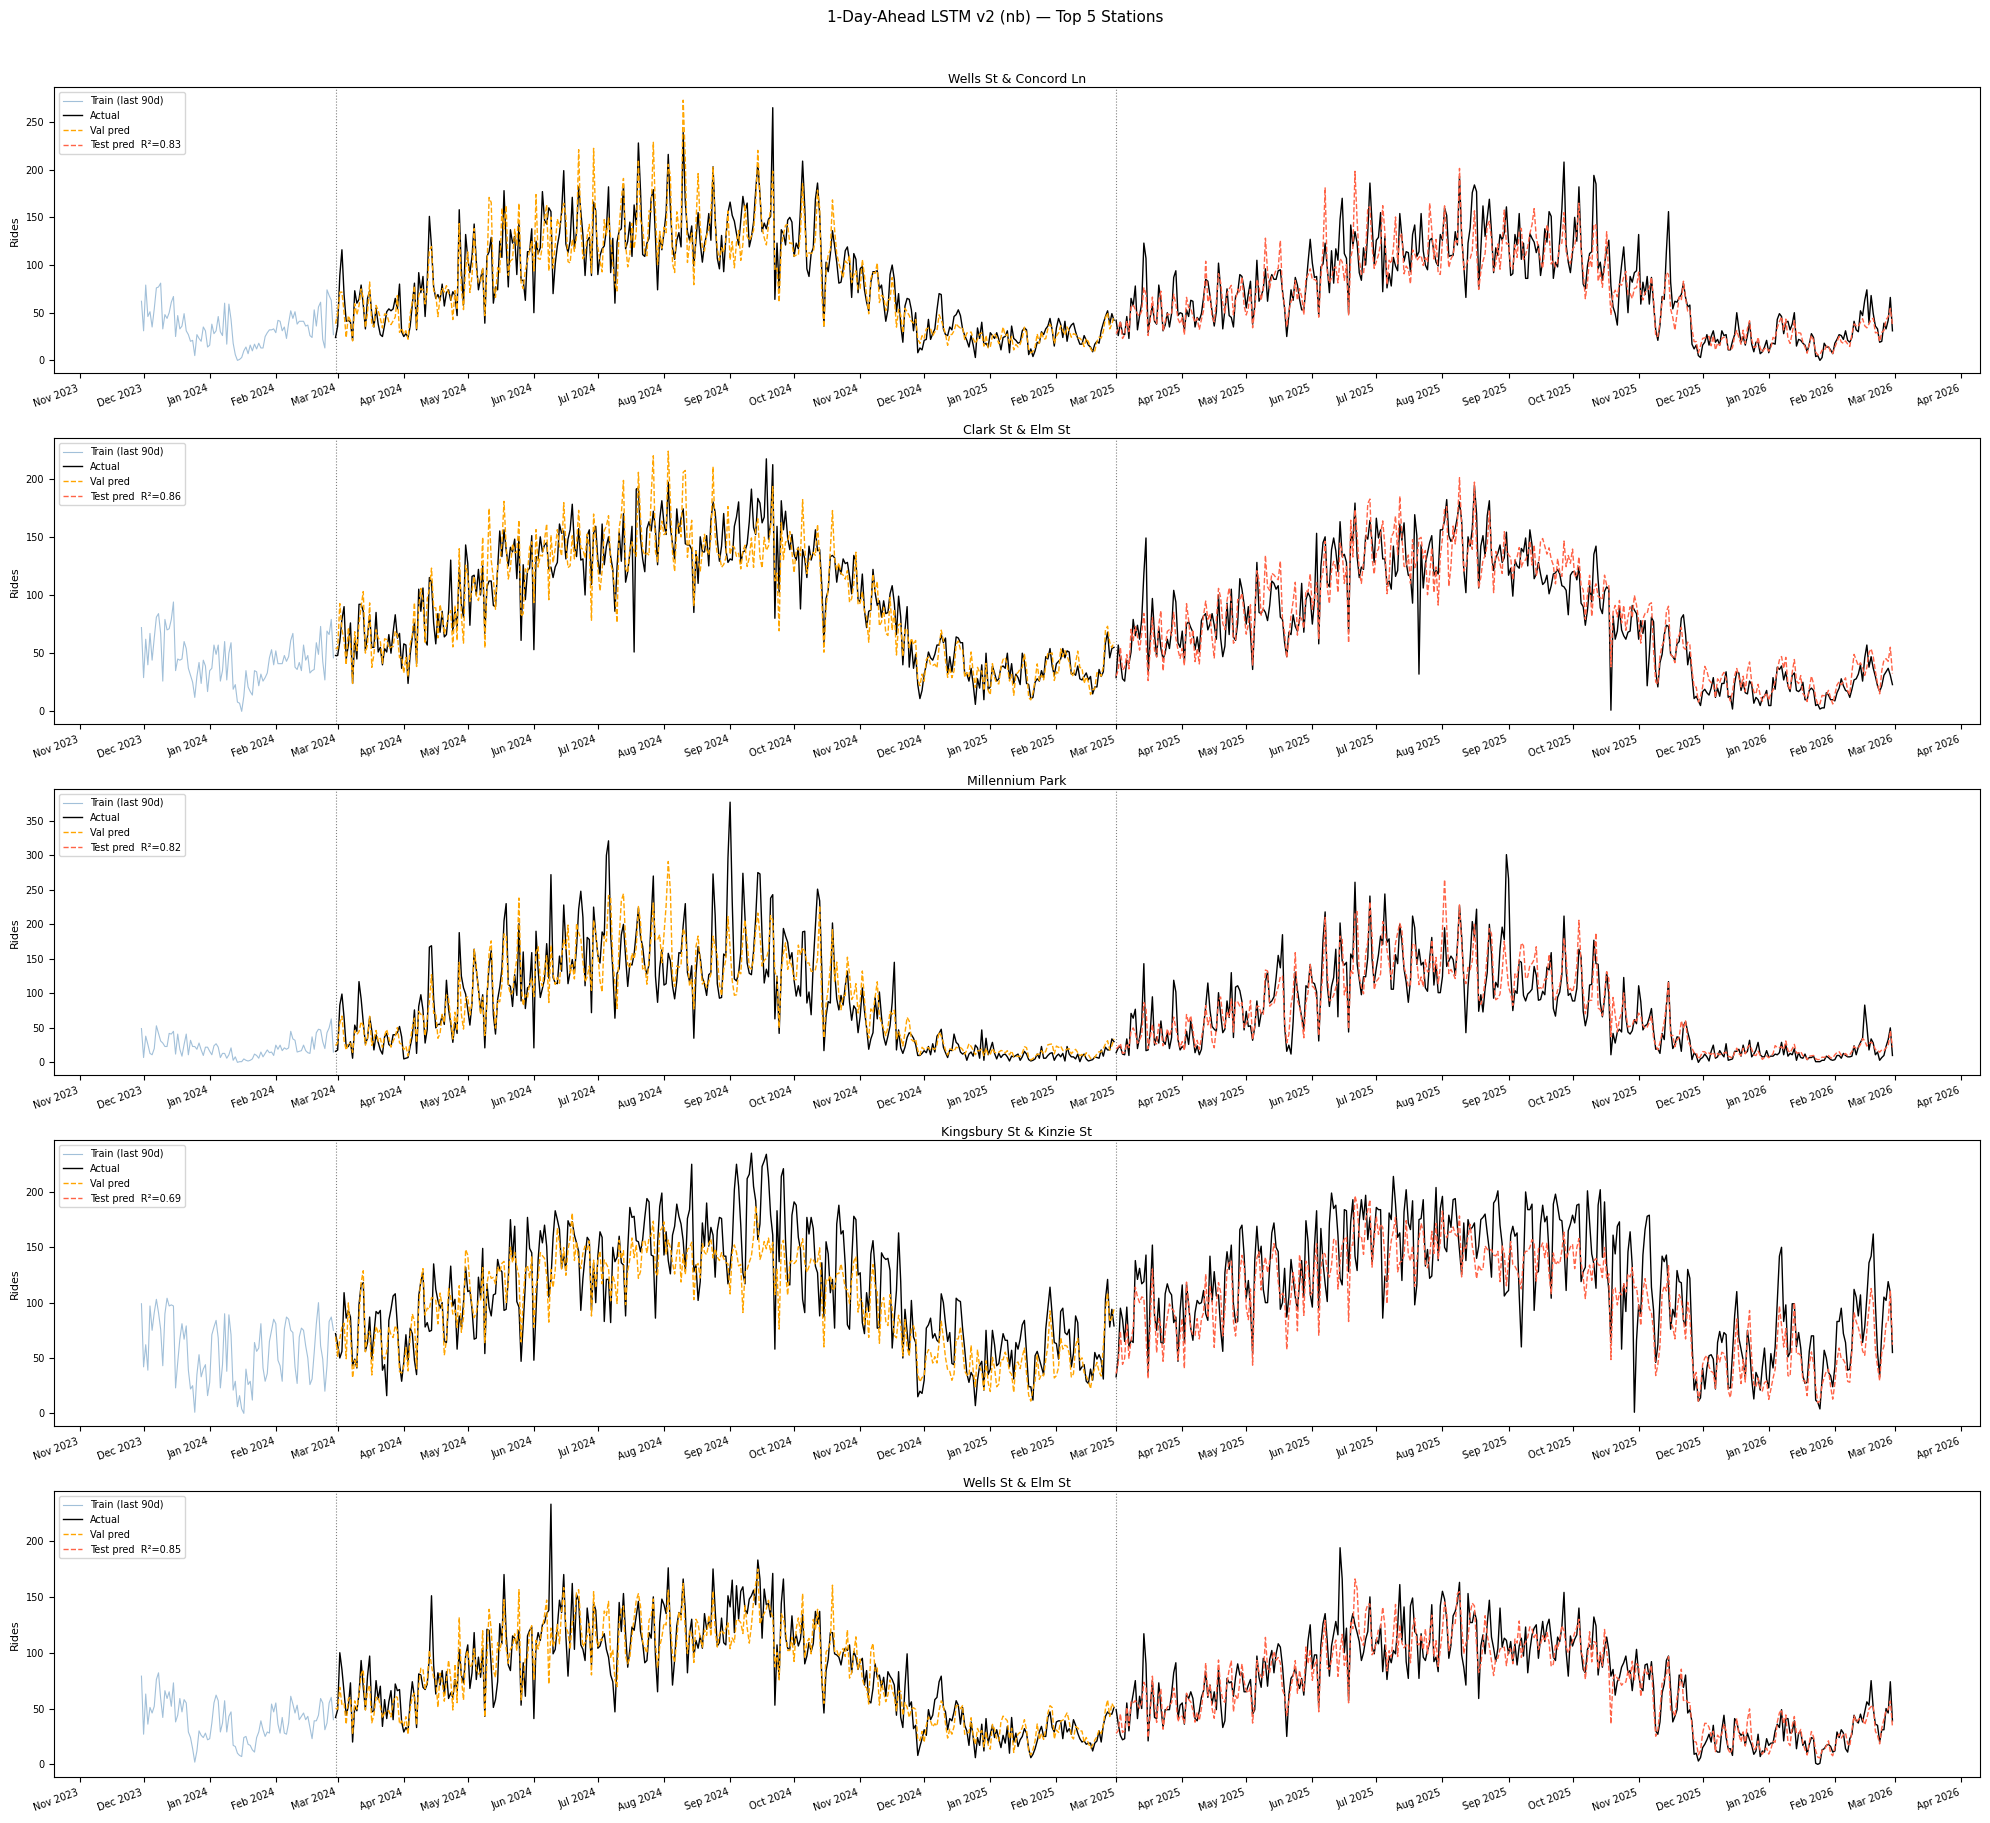

In [16]:
top5 = (df[df["date"] < val_start].groupby("start_station_name")["total_rides"]
        .sum().sort_values(ascending=False).head(5).index.tolist())

CONTEXT_DAYS = 90
fig, axes = plt.subplots(5, 1, figsize=(20, 18))
for ax, name in zip(axes, top5):
    tr     = df[(df["start_station_name"] == name) & (df["date"] < val_start)].sort_values("date")
    tr_ctx = tr[tr["date"] >= tr["date"].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl = val_eval[val_eval["start_station_name"] == name].sort_values("date")
    te = test_eval[test_eval["start_station_name"] == name].sort_values("date")
    r2_s = per_station.loc[name, "r2"] if name in per_station.index else float("nan")
    ax.plot(tr_ctx["date"], tr_ctx["total_rides"], color="steelblue", alpha=0.5, linewidth=0.8, label="Train (last 90d)")
    ax.axvline(vl["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.axvline(te["date"].min(), color="grey", linestyle=":", linewidth=0.8)
    ax.plot(vl["date"], vl["total_rides"], color="black",  linewidth=1, label="Actual")
    ax.plot(vl["date"], vl["pred"],        color="orange", linestyle="--", linewidth=1, label="Val pred")
    ax.plot(te["date"], te["total_rides"], color="black",  linewidth=1)
    ax.plot(te["date"], te["pred"],        color="tomato", linestyle="--", linewidth=1, label=f"Test pred  R²={r2_s:.2f}")
    ax.set_title(name, fontsize=9, pad=3); ax.set_ylabel("Rides", fontsize=8)
    ax.legend(fontsize=7, loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha="right", fontsize=7); ax.tick_params(axis="y", labelsize=7)
fig.suptitle(f"1-Day-Ahead LSTM v2 ({LOSS_MODE}) — Top 5 Stations", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

## 8. Save

In [17]:
os.makedirs("../../models", exist_ok=True)
out_path = f"../../models/lstm_station_1day_v2_{LOSS_MODE}.pt"
torch.save({
    "state_dict": best_state,
    "config": dict(LOSS_MODE=LOSS_MODE, SEQ_LEN=SEQ_LEN, HIDDEN=HIDDEN, NUM_LAYERS=NUM_LAYERS, STN_DIM=STN_DIM,
                   GEO_DIM=GEO_DIM, N_FOURIER=N_FOURIER, T_MIN=T_MIN, T_MAX=T_MAX, init_log_rate=init_log_rate,
                   DROPOUT=DROPOUT, PATIENCE=PATIENCE),
    "columns": dict(SEQ_COLS=SEQ_COLS, STATION_COLS=STATION_COLS, GEO_COLS=GEO_COLS, STATIC_COLS=STATIC_COLS,
                    EVENT_COLS=EVENT_COLS, WEATHER_COLS=WEATHER_COLS, W_TARGET_COLS=W_TARGET_COLS,
                    FLOW_COLS=FLOW_COLS, CAL_COLS=CAL_COLS, SPORTS_COLS=SPORTS_COLS, HOLIDAY_COLS=HOLIDAY_COLS,
                    ACADEMIC_COLS=ACADEMIC_COLS),
    "scalers": dict(seq=seq_scaler, w=w_scaler, geo=geo_scaler, static=static_scaler),
    "metrics": metrics_overall.to_dict(),
    "split": dict(val_start=str(val_start.date()), test_start=str(test_start.date())),
}, out_path)
print("Saved", out_path)


Saved ../../models/lstm_station_1day_v2_nb.pt
